In [2]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")

import itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.config import PROCESSED, ROOT
from src.indicators import atr
from src.backtest import backtest, placebo_direccion
from src.strategies import señales_reversion

df = pd.read_parquet(PROCESSED)
df["atr"] = atr(df, 14)

es_IS = df.index.year <= 2024          # máscara in-sample
df_is = df[es_IS]                      # SOLO 2020–2024 (el OOS no se toca)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:

filas = []
for k, sl, tp in itertools.product([1.0, 1.5, 2.0, 2.5], [1.5, 2.0], [0.5, 1.0, 1.5]):
    señ = señales_reversion(df, k=k)[es_IS]                         # señales recortadas a IS
    p = dict(sl_mult=sl, tp_mult=tp, max_velas=12, coste=0.25)
    t = backtest(df_is, señ, **p)
    plac = placebo_direccion(df_is, señ, n_sim=50, **p)
    filas.append({"k": k, "sl": sl, "tp": tp, "n": len(t),
                  "expR": t["R"].mean(),
                  "placebo": plac.mean(),
                  "ventaja": t["R"].mean() - plac.mean(),
                  "p_valor": (plac >= t["R"].mean()).mean()})

grid_A = pd.DataFrame(filas)
grid_A.to_parquet(ROOT / "reports" / "grid_A_IS.parquet")
grid_A.sort_values("ventaja", ascending=False).round(3).head(10)

,k,sl,tp,n,expR,placebo,ventaja,p_valor
20,2.5,1.5,1.5,1342,-0.073,-0.160,0.087,0.00
14,2.0,1.5,1.5,1752,-0.086,-0.158,0.072,0.00
23,2.5,2.0,1.5,1342,-0.066,-0.135,0.069,0.00
19,2.5,1.5,1.0,1342,-0.094,-0.163,0.069,0.00
22,2.5,2.0,1.0,1342,-0.082,-0.137,0.055,0.00
17,2.0,2.0,1.5,1752,-0.069,-0.122,0.053,0.00
13,2.0,1.5,1.0,1752,-0.106,-0.158,0.051,0.00
8,1.5,1.5,1.5,2184,-0.101,-0.152,0.051,0.02
18,2.5,1.5,0.5,1342,-0.124,-0.172,0.048,0.00
21,2.5,2.0,0.5,1342,-0.091,-0.135,0.044,0.00


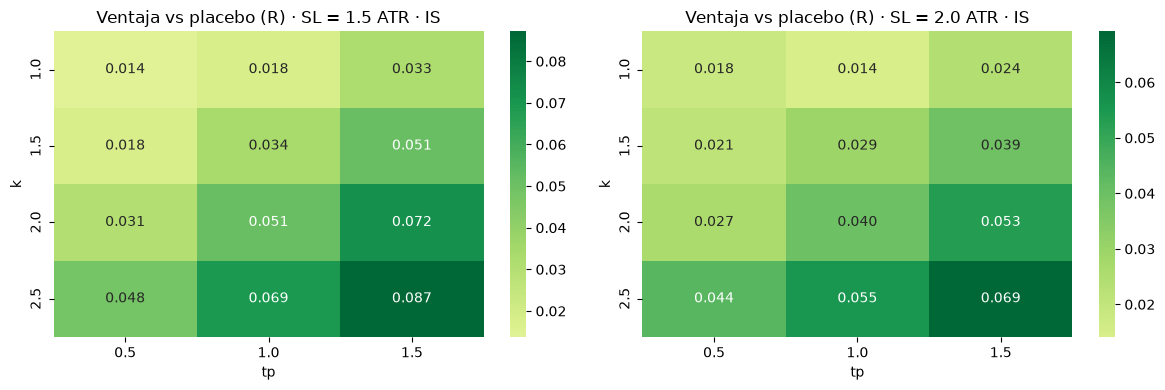

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, sl in zip(axes, [1.5, 2.0]):
    tabla = grid_A[grid_A.sl == sl].pivot(index="k", columns="tp", values="ventaja")
    sns.heatmap(tabla, annot=True, fmt=".3f", cmap="RdYlGn", center=0, ax=ax)
    ax.set_title(f"Ventaja vs placebo (R) · SL = {sl} ATR · IS")
plt.tight_layout(); plt.show()

In [5]:
filas_ext = []
for k, sl, tp in itertools.product([3.0, 3.5], [1.5, 2.0], [1.0, 1.5]):
    señ = señales_reversion(df, k=k)[es_IS]
    p = dict(sl_mult=sl, tp_mult=tp, max_velas=12, coste=0.25)
    t = backtest(df_is, señ, **p)
    plac = placebo_direccion(df_is, señ, n_sim=50, **p)
    filas_ext.append({"k": k, "sl": sl, "tp": tp, "n": len(t), "expR": t["R"].mean(),
                      "placebo": plac.mean(), "ventaja": t["R"].mean() - plac.mean(),
                      "p_valor": (plac >= t["R"].mean()).mean()})
pd.DataFrame(filas_ext).round(3)

,k,sl,tp,n,expR,placebo,ventaja,p_valor
0,3.0,1.5,1.0,939,-0.119,-0.163,0.044,0.04
1,3.0,1.5,1.5,939,-0.106,-0.157,0.051,0.04
2,3.0,2.0,1.0,939,-0.093,-0.128,0.035,0.02
3,3.0,2.0,1.5,939,-0.081,-0.121,0.040,0.02
4,3.5,1.5,1.0,636,-0.123,-0.144,0.021,0.24
5,3.5,1.5,1.5,636,-0.118,-0.148,0.031,0.20
6,3.5,2.0,1.0,636,-0.095,-0.114,0.018,0.18
7,3.5,2.0,1.5,636,-0.086,-0.111,0.025,0.16


In [6]:
es_OOS = df.index.year >= 2025
df_oos = df[es_OOS]

p_A = dict(sl_mult=2.0, tp_mult=1.5, max_velas=12, coste=0.25)
señ_oos = señales_reversion(df, k=2.5)[es_OOS]

t_oos = backtest(df_oos, señ_oos, **p_A)
plac_oos = placebo_direccion(df_oos, señ_oos, n_sim=500, **p_A)

r = t_oos["R"]
print(f"OOS  trades={len(r)}  expR={r.mean():.3f}  placebo={plac_oos.mean():.3f}  "
      f"ventaja={r.mean() - plac_oos.mean():.3f}  p={(plac_oos >= r.mean()).mean():.3f}")

OOS  trades=482  expR=-0.082  placebo=-0.042  ventaja=-0.040  p=0.910


In [7]:
filas = []
señ_full = señales_reversion(df, k=2.5)
for año in range(2020, 2027):
    m = df.index.year == año
    t = backtest(df[m], señ_full[m], **p_A)
    plac = placebo_direccion(df[m], señ_full[m], n_sim=100, **p_A)
    filas.append({"año": año, "n": len(t), "expR": t["R"].mean(),
                  "ventaja": t["R"].mean() - plac.mean(),
                  "p": (plac >= t["R"].mean()).mean()})
pd.DataFrame(filas).set_index("año").round(3)

,n,expR,ventaja,p
año,,,,
2020,249,-0.056,0.061,0.12
2021,273,-0.075,0.074,0.06
2022,293,-0.095,0.013,0.42
2023,257,-0.015,0.116,0.02
2024,270,-0.081,0.051,0.16
2025,277,-0.101,-0.042,0.79
2026,205,-0.057,-0.051,0.79
